In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from IPython.display import display
import math
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
import joblib
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, learning_curve
import joblib
import json

In [2]:
df = pd.read_csv("student_career_success_dataset.csv")
print(df.head())
print(df.shape)
student_ids = df["Student_ID"].copy()

  Student_ID  Age  Gender University_Year                   Major  \
0   ST000001   22    Male       Sophomore        Computer Science   
1   ST000002   20  Female        Freshman        Computer Science   
2   ST000003   23    Male          Senior  Information Technology   
3   ST000004   23  Female          Senior  Information Technology   
4   ST000005   23  Female          Senior    Software Engineering   

   Attendance_Percentage  Study_Hours_Per_Week  CGPA Academic_Performance  \
0                     86                    21  3.28                 Good   
1                     64                    18  2.53                 Poor   
2                     75                    19  2.83              Average   
3                     80                    19  2.80              Average   
4                     73                    19  2.93              Average   

   Programming_Skill  ...  Teamwork  Problem_Solving  English_Proficiency  \
0                  9  ...         7          

In [3]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  object 
 3   University_Year        50000 non-null  object 
 4   Major                  50000 non-null  object 
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  object 
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  object 
 14  Internships            50000 non-null  int64  
 15  Le

In [4]:

selected_features = [
    "CGPA",
    "Programming_Skill",
    "Problem_Solving",
    "Projects_Completed",
    "Internships",
    "Certifications",
    "Communication_Skills",
    "English_Proficiency",
    "Resume_Score",
    "Interview_Score"
]
target = "Placement_Status"

# إنشاء نسخة نظيفة
selected_df = df[selected_features + [target]].copy()

print("\nSelected Dataset Shape:")
print(selected_df.shape)

print("\nFirst 5 Rows:")
print(selected_df.head())


Selected Dataset Shape:
(50000, 11)

First 5 Rows:
   CGPA  Programming_Skill  Problem_Solving  Projects_Completed  Internships  \
0  3.28                  9                8                  10            5   
1  2.53                  6                5                   6            2   
2  2.83                  8                7                   9            3   
3  2.80                  5                6                   6            2   
4  2.93                  9                9                  10            3   

   Certifications  Communication_Skills English_Proficiency  Resume_Score  \
0               1                     9            Advanced           100   
1               0                     5               Basic            80   
2               0                     7            Advanced           100   
3               3                     6        Intermediate            85   
4               1                    10            Advanced           100   

   I

In [5]:
print(selected_df.isnull().sum())

CGPA                    0
Programming_Skill       0
Problem_Solving         0
Projects_Completed      0
Internships             0
Certifications          0
Communication_Skills    0
English_Proficiency     0
Resume_Score            0
Interview_Score         0
Placement_Status        0
dtype: int64


In [6]:
print(selected_df.duplicated().sum())

72


In [7]:


df_corrupted = selected_df.copy()
np.random.seed(42)
n_missing = 100

rows = np.random.choice(
    df_corrupted.index,
    size=n_missing,
    replace=False
)

cols = np.random.choice(
    selected_features,
    size=n_missing,
    replace=True
)

for row, col in zip(rows, cols):
    df_corrupted.loc[row, col] = np.nan

print(df_corrupted.isnull().sum())
print("Total Missing:", df_corrupted.isnull().sum().sum())


CGPA                    10
Programming_Skill        9
Problem_Solving         12
Projects_Completed      11
Internships             12
Certifications           7
Communication_Skills    10
English_Proficiency      8
Resume_Score             7
Interview_Score         14
Placement_Status         0
dtype: int64
Total Missing: 100


In [8]:

duplicate_rows = df_corrupted.sample(
    n=30,
    random_state=42
)

df_corrupted = pd.concat(
    [df_corrupted, duplicate_rows],
    ignore_index=True
)

# Check duplicates
print("Duplicate Rows:", df_corrupted.duplicated().sum())
print("Dataset Shape:", df_corrupted.shape)


Duplicate Rows: 101
Dataset Shape: (50030, 11)


In [9]:
numeric_cols = df_corrupted.select_dtypes(
    include=["int64", "float64"]
).columns

outlier_results = []

for col in numeric_cols:

    Q1 = df_corrupted[col].quantile(0.25)
    Q3 = df_corrupted[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_corrupted[
        (df_corrupted[col] < lower_bound) |
        (df_corrupted[col] > upper_bound)
    ]

    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df_corrupted) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,CGPA,2.31,3.91,267,0.53
1,Programming_Skill,3.00,11.00,88,0.18
2,Problem_Solving,3.00,11.00,192,0.38
3,Projects_Completed,2.50,14.50,806,1.61
4,Internships,0.00,8.00,0,0.00
5,Certifications,-2.00,6.00,29,0.06
6,Communication_Skills,2.50,14.50,0,0.00
7,Resume_Score,87.50,107.50,6354,12.70
8,Interview_Score,44.50,112.50,490,0.98


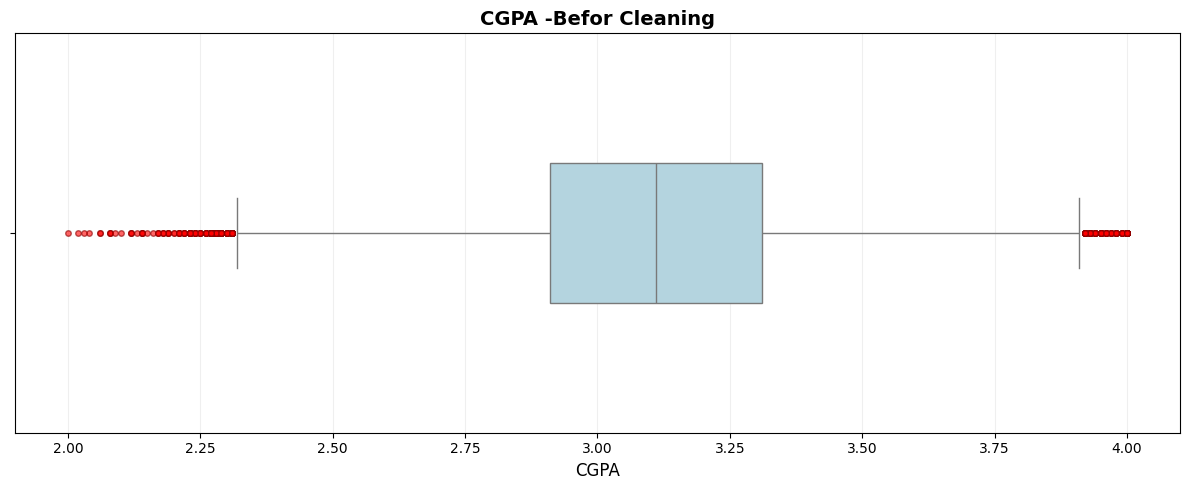

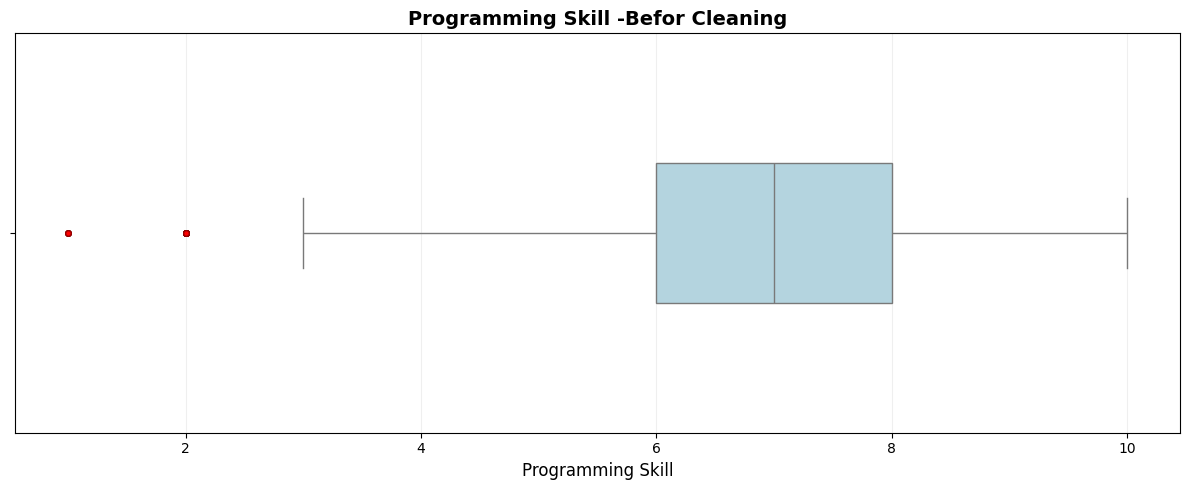

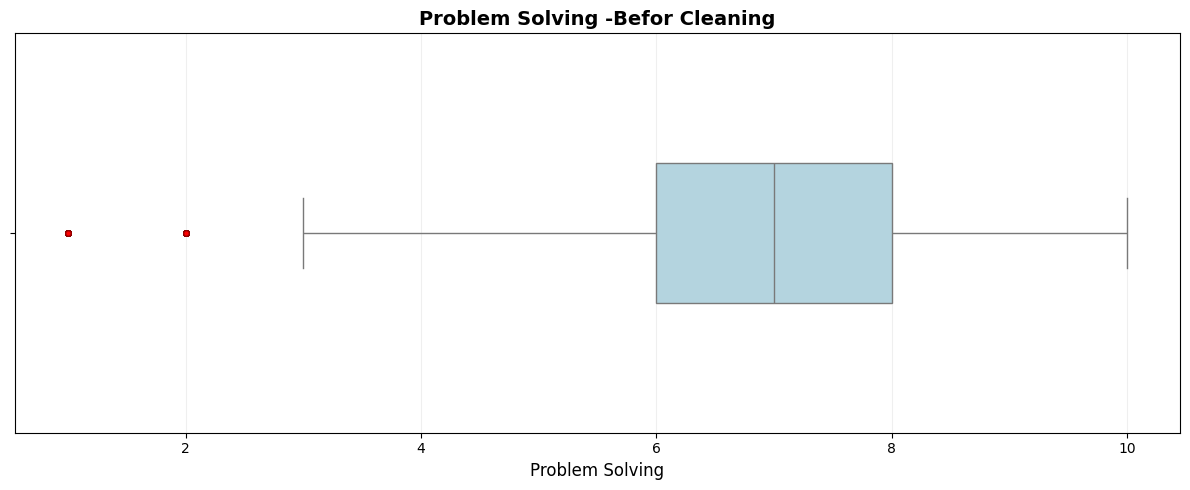

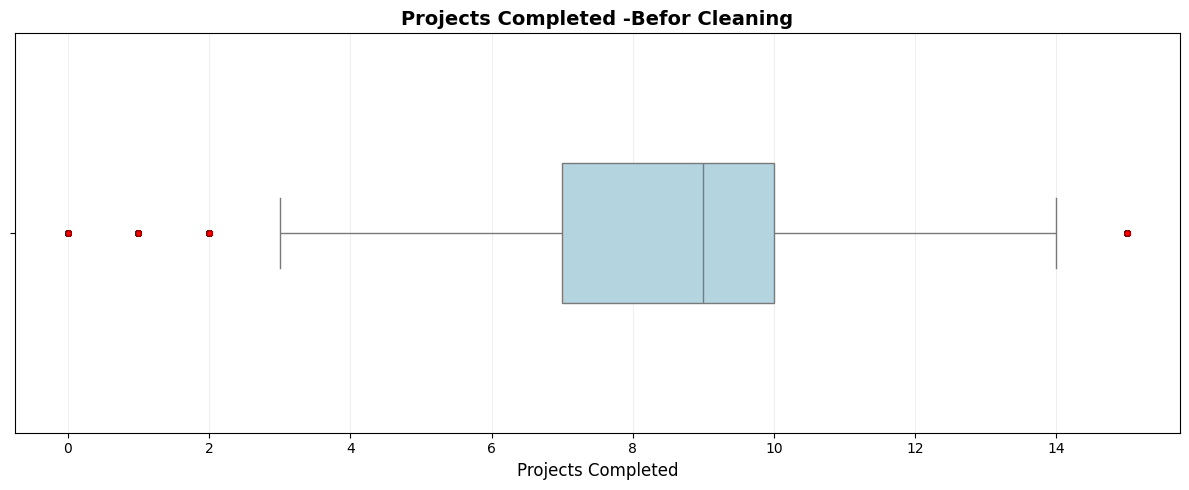

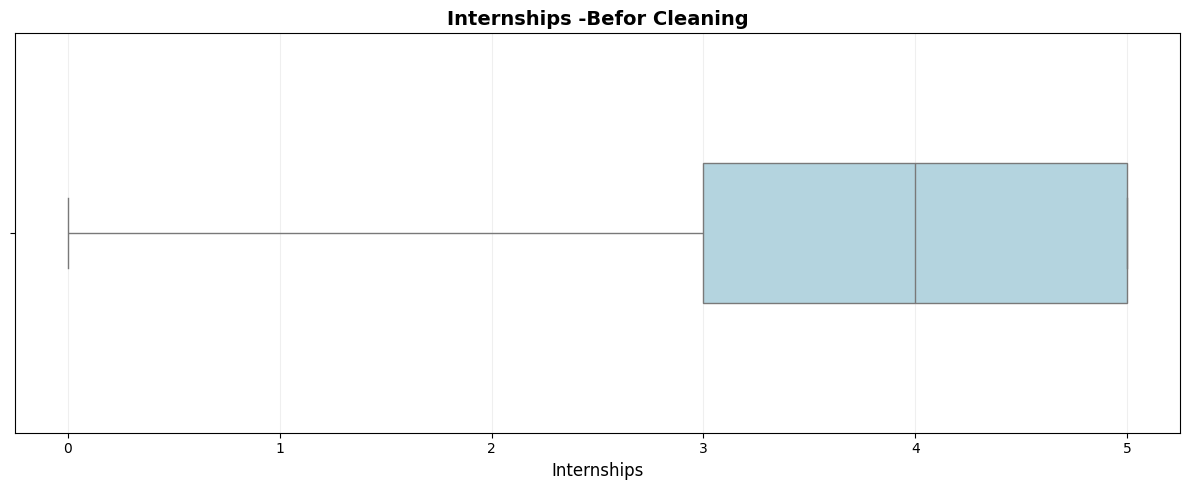

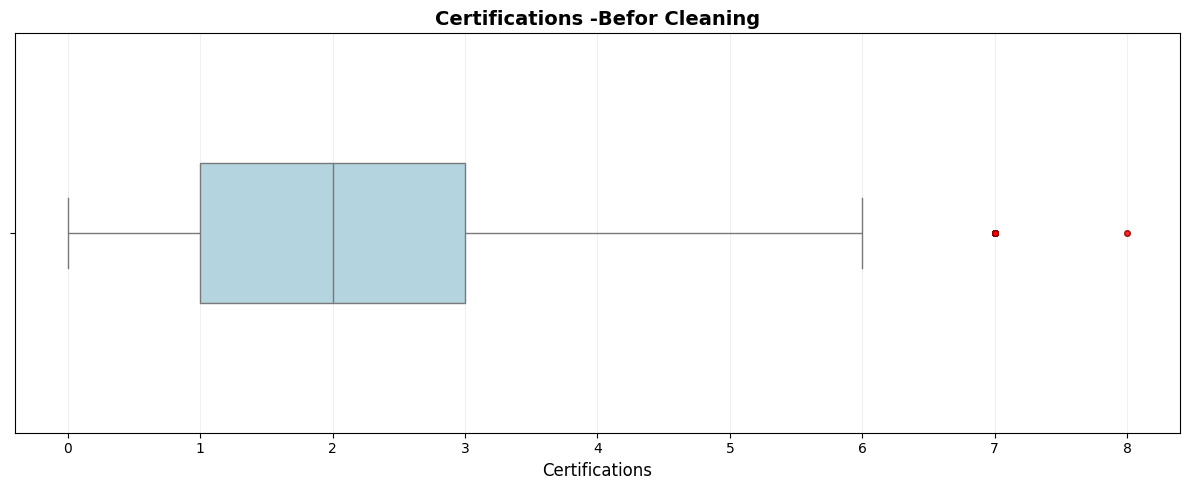

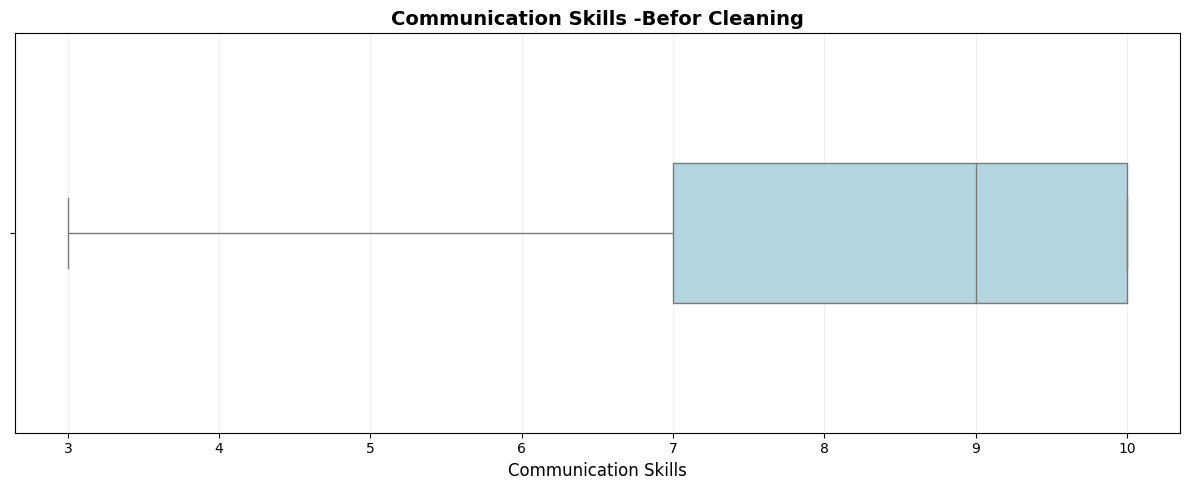

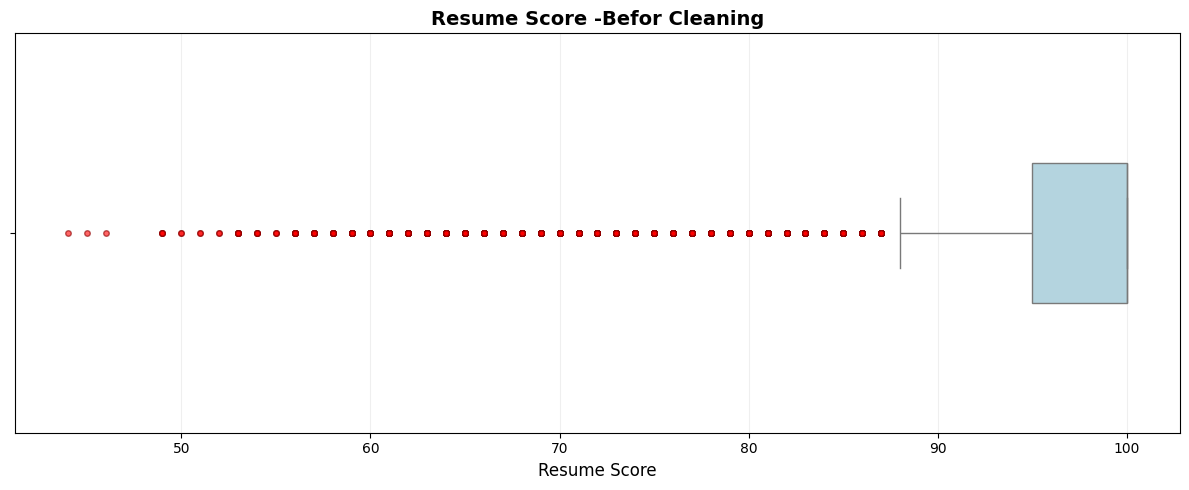

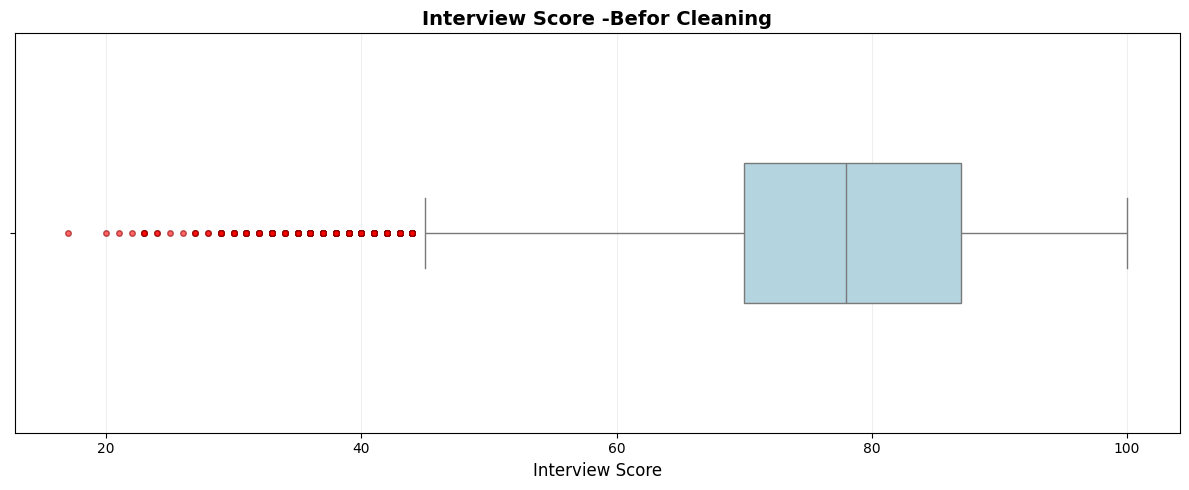

In [10]:
cols_to_plot = [
    "CGPA",
    "Programming_Skill",
    "Problem_Solving",
    "Projects_Completed",
    "Internships",
    "Certifications",
    "Communication_Skills",
    "Resume_Score",
    "Interview_Score"
]

for col in cols_to_plot:
    plt.figure(figsize=(12, 5))
    
    sns.boxplot(
        x=df_corrupted[col],
        color="lightblue",
        width=0.35,
        flierprops={
            "marker": "o",
            "markerfacecolor": "red",
            "markeredgecolor": "darkred",
            "markersize": 4,
            "alpha": 0.6
        }
    )
    
    col_name = col.replace('_', ' ')
    plt.title(
        f"{col_name} -Befor Cleaning",
        fontsize=14,
        fontweight="bold"
    )
    
    plt.xlabel(col_name, fontsize=12)
    plt.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()


In [11]:
eng_mapping = {'Basic': 1, 'Intermediate': 2, 'Advanced': 3}
df_corrupted['English_Proficiency'] = df_corrupted['English_Proficiency'].map(eng_mapping)

In [12]:

df_before = df_corrupted.copy(deep=True)

df_cleaned = df_before.copy(deep=True)



In [13]:
duplicates_before = df_cleaned.duplicated().sum()

df_cleaned = df_cleaned.drop_duplicates().copy()

print("Duplicates removed:", duplicates_before)
print("Remaining duplicates:", df_cleaned.duplicated().sum())
print("Remaining rows:", len(df_cleaned))

Duplicates removed: 101
Remaining duplicates: 0
Remaining rows: 49929


In [14]:

rows_before = len(df_cleaned)

df_cleaned = df_cleaned.dropna().copy()

print("Rows removed:", rows_before - len(df_cleaned))
print("Remaining rows:", len(df_cleaned))
print("Remaining missing values:", df_cleaned.isnull().sum().sum())


Rows removed: 100
Remaining rows: 49829
Remaining missing values: 0


In [15]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Split data into training and testing sets
train_df, test_df = train_test_split(
    df_cleaned,
    test_size=0.20,
    random_state=42,
    stratify=df_cleaned["Placement_Status"]
)

train_df = train_df.copy()
test_df = test_df.copy()

# Select numeric features (exclude target and English proficiency)
numeric_cols = train_df.select_dtypes(include="number").columns
numeric_cols = numeric_cols.drop(
    ["Placement_Status", "English_Proficiency","Certifications"],
    errors="ignore"
)

# Handle outliers using IQR (training data only)
for col in numeric_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    train_df[col] = train_df[col].clip(lower_bound, upper_bound)
    test_df[col] = test_df[col].clip(lower_bound, upper_bound)

print("Outliers handled successfully!")
print("Training:", train_df.shape)
print("Test:", test_df.shape)


Outliers handled successfully!
Training: (39863, 11)
Test: (9966, 11)


In [16]:
df_after = pd.concat([train_df, test_df]).sort_index()

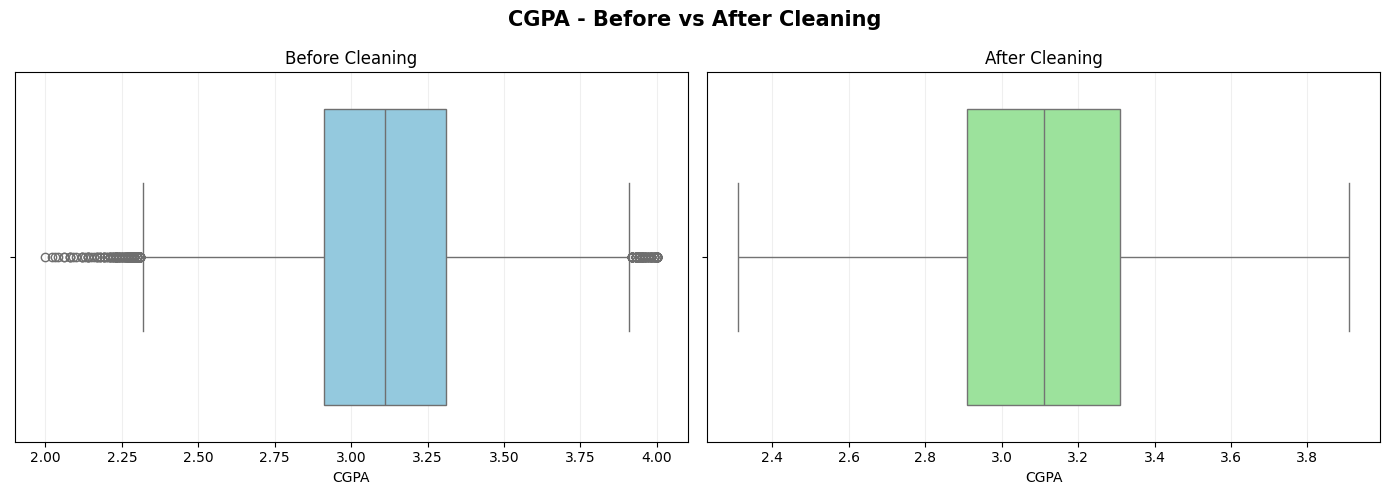

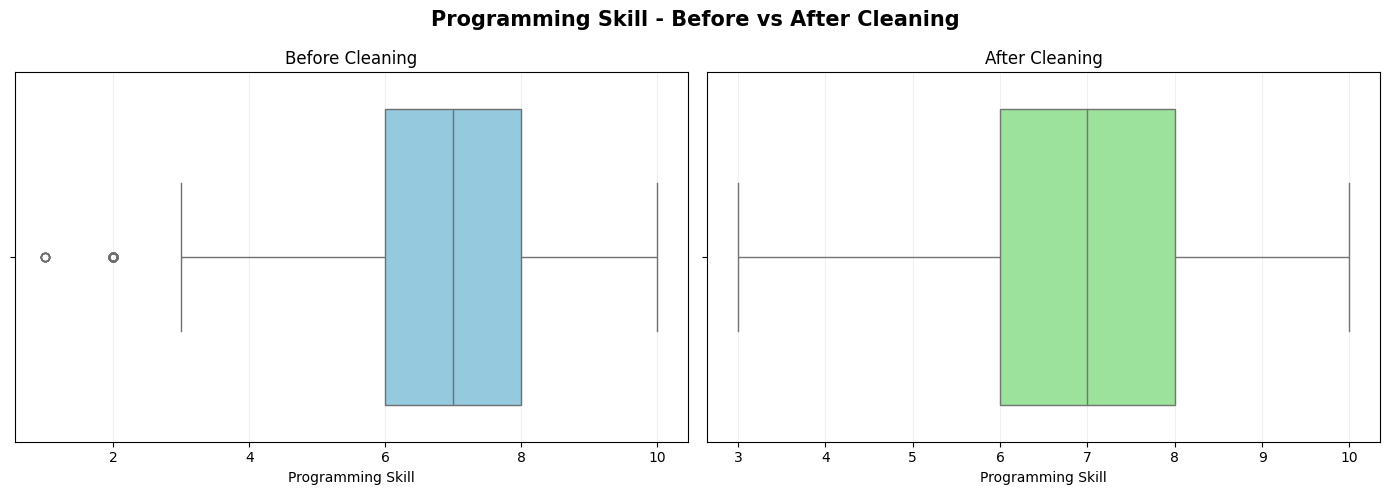

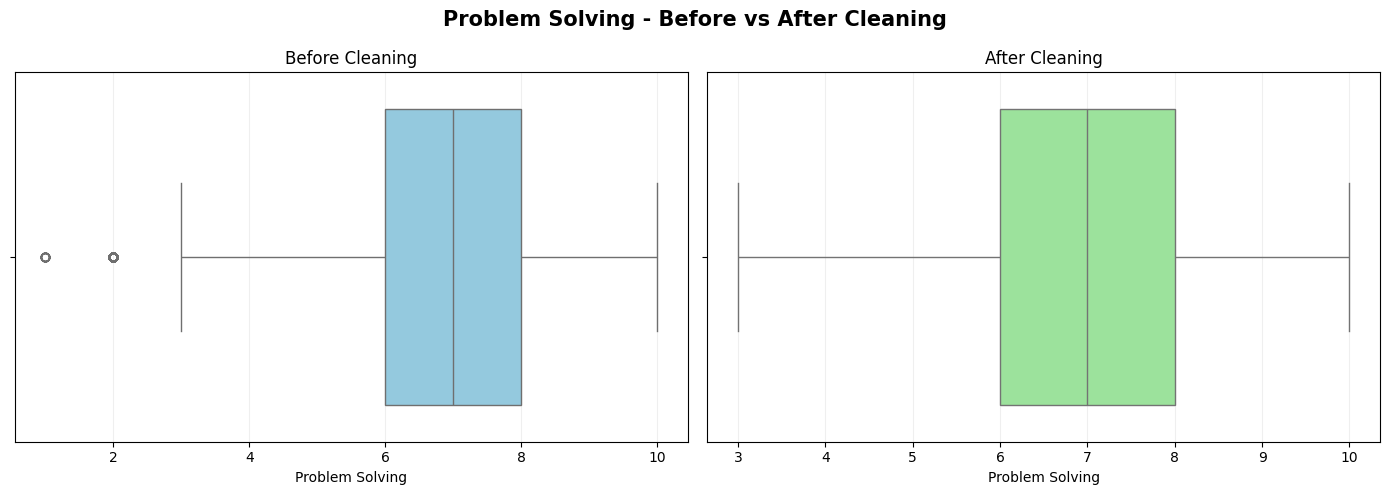

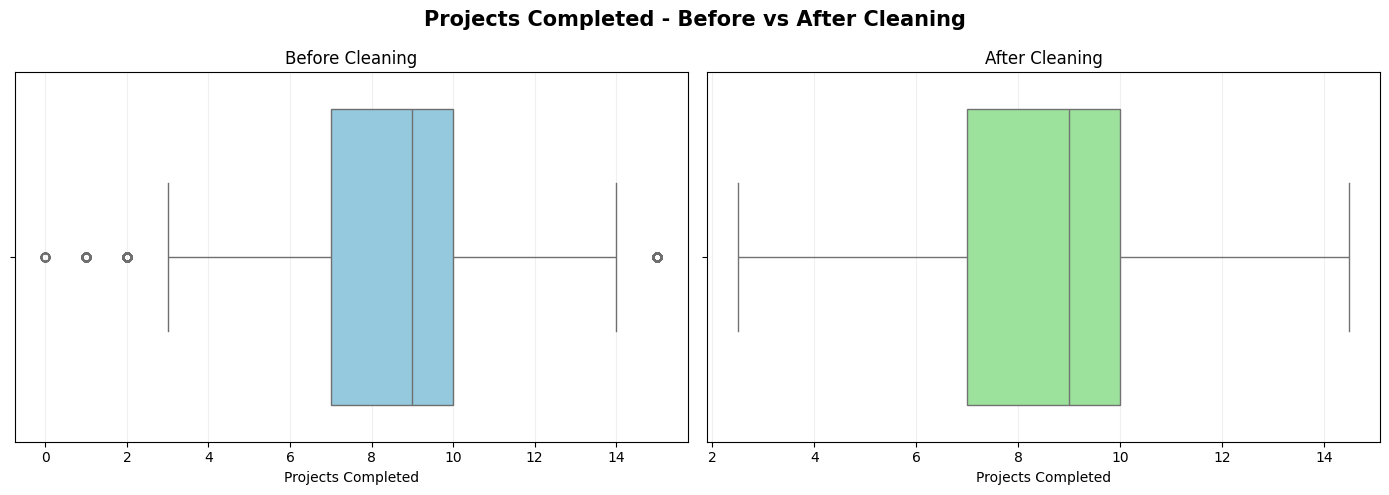

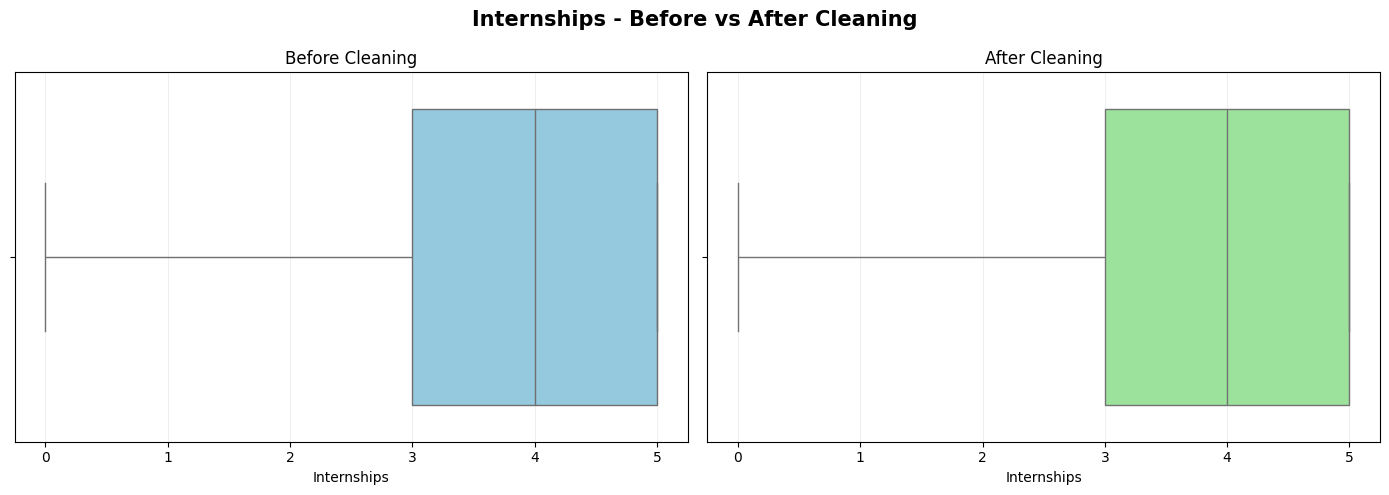

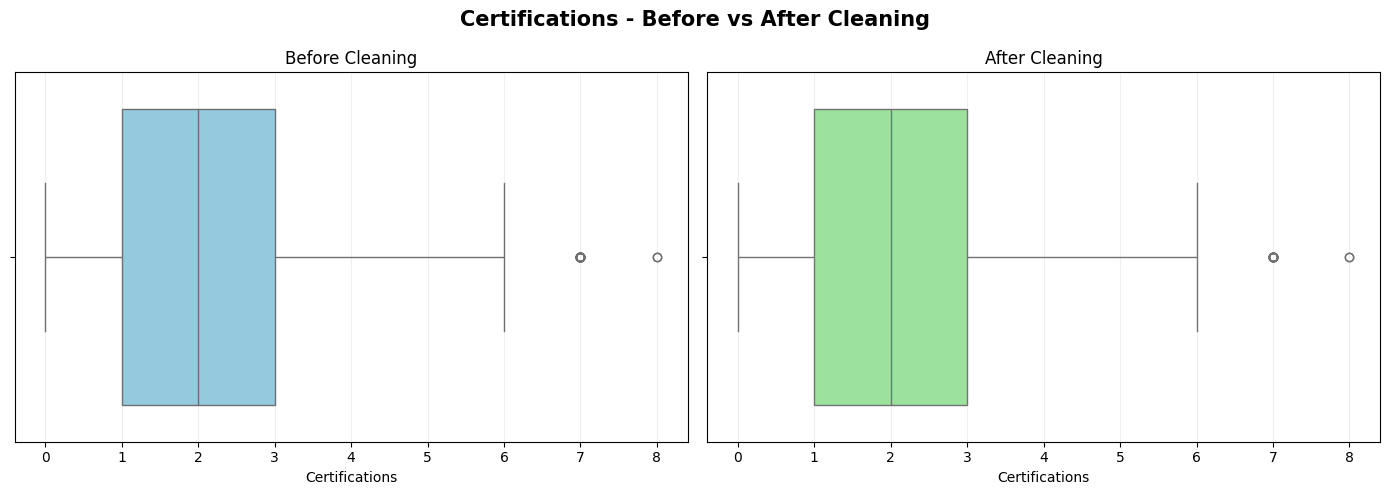

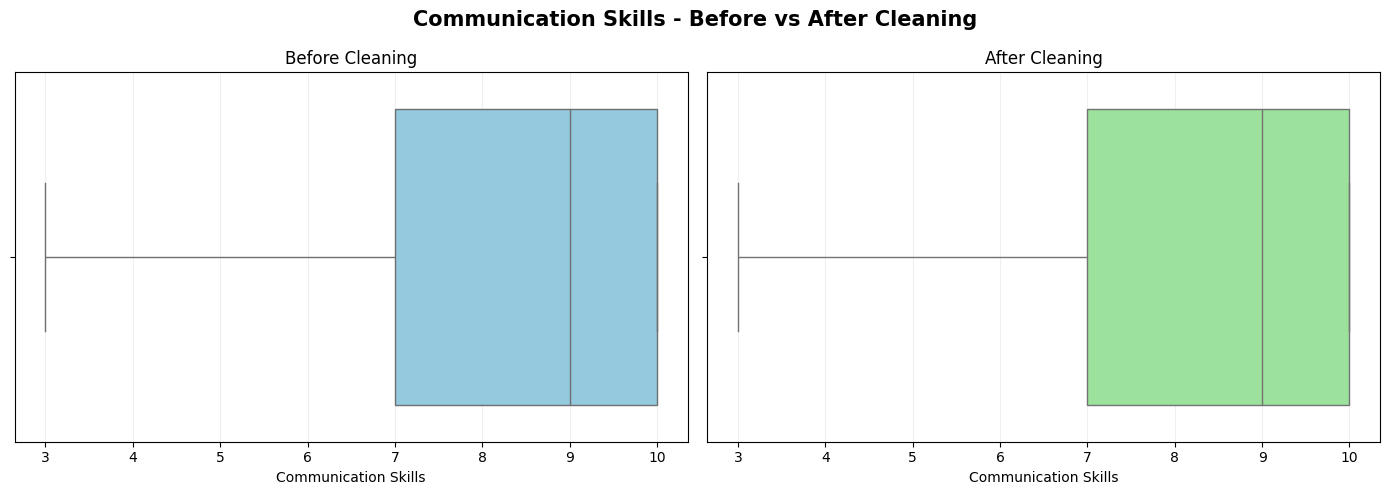

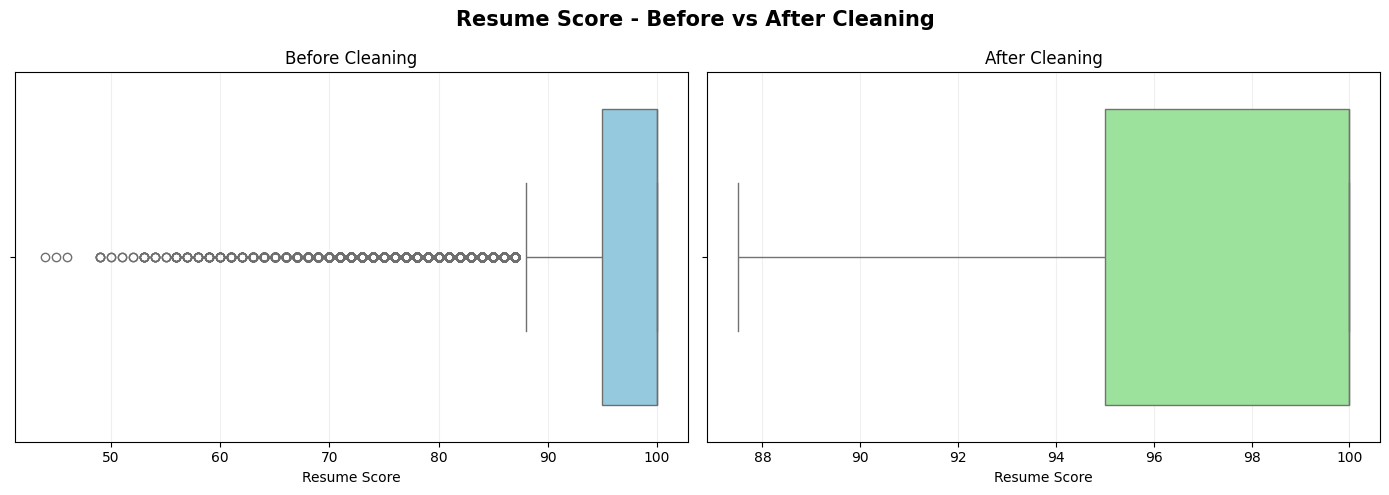

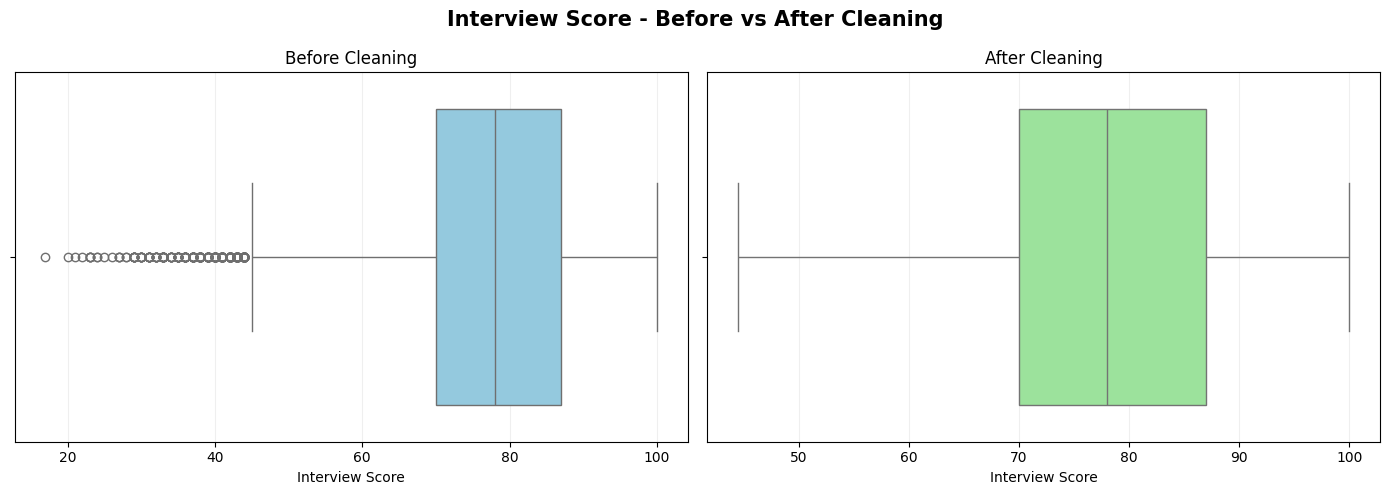

In [17]:

cols_to_plot = [
    "CGPA",
    "Programming_Skill",
    "Problem_Solving",
    "Projects_Completed",
    "Internships",
    "Certifications",
    "Communication_Skills",
    "Resume_Score",
    "Interview_Score"
]

df_after = pd.concat([train_df, test_df]).sort_index()

for col in cols_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.boxplot(
        x=df_before[col],
        ax=axes[0],
        color="skyblue"
    )
    axes[0].set_title("Before Cleaning")
    axes[0].set_xlabel(col.replace('_', ' '))

    sns.boxplot(
        x=df_after[col],
        ax=axes[1],
        color="lightgreen"
    )
    axes[1].set_title("After Cleaning")
    axes[1].set_xlabel(col.replace('_', ' '))

    for ax in axes:
        ax.grid(axis="x", alpha=0.2)

    plt.suptitle(
        f"{col.replace('_', ' ')} - Before vs After Cleaning",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


In [18]:
cleaning_summary = pd.DataFrame({
    "Metric": ["Rows", "Missing cells", "Duplicate rows"],
    "Before": [len(df_before), df_before.isna().sum().sum(), df_before.duplicated().sum()],
    "After": [len(df_cleaned), df_cleaned.isna().sum().sum(), df_cleaned.duplicated().sum()]
})
display(cleaning_summary)
display(df_before.describe().round(2))
display(df_cleaned.describe().round(2))
from pathlib import Path
Path("milestone3_outputs").mkdir(exist_ok=True)
cleaning_summary.to_csv("milestone3_outputs/cleaning_summary.csv", index=False)


,Metric,Before,After
0,Rows,50030,49829
1,Missing cells,130,0
2,Duplicate rows,101,0


,CGPA,Programming_Skill,Problem_Solving,Projects_Completed,Internships,Certifications,Communication_Skills,English_Proficiency,Resume_Score,Interview_Score
count,50018.00,50018.00,50017.00,50014.00,50014.00,50022.00,50017.00,50018.00,50020.00,50012.00
mean,3.11,7.14,7.18,8.62,4.05,1.72,8.44,2.78,96.05,77.52
std,0.29,1.51,1.67,2.51,1.01,1.37,1.39,0.44,7.33,12.58
min,2.00,1.00,1.00,0.00,0.00,0.00,3.00,1.00,44.00,17.00
25%,2.91,6.00,6.00,7.00,3.00,1.00,7.00,3.00,95.00,70.00
50%,3.11,7.00,7.00,9.00,4.00,2.00,9.00,3.00,100.00,78.00
75%,3.31,8.00,8.00,10.00,5.00,3.00,10.00,3.00,100.00,87.00
max,4.00,10.00,10.00,15.00,5.00,8.00,10.00,3.00,100.00,100.00


,CGPA,Programming_Skill,Problem_Solving,Projects_Completed,Internships,Certifications,Communication_Skills,English_Proficiency,Resume_Score,Interview_Score
count,49829.00,49829.00,49829.00,49829.00,49829.00,49829.00,49829.00,49829.00,49829.00,49829.00
mean,3.11,7.14,7.17,8.62,4.05,1.72,8.43,2.78,96.04,77.50
std,0.29,1.51,1.67,2.51,1.01,1.37,1.39,0.44,7.33,12.58
min,2.00,1.00,1.00,0.00,0.00,0.00,3.00,1.00,44.00,17.00
25%,2.91,6.00,6.00,7.00,3.00,1.00,7.00,3.00,95.00,70.00
50%,3.11,7.00,7.00,9.00,4.00,2.00,9.00,3.00,100.00,78.00
75%,3.31,8.00,8.00,10.00,5.00,3.00,10.00,3.00,100.00,87.00
max,4.00,10.00,10.00,15.00,5.00,8.00,10.00,3.00,100.00,100.00


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from IPython.display import Markdown
from pathlib import Path

output_dir = Path("milestone3_outputs")
output_dir.mkdir(exist_ok=True)

model_data = df_cleaned.copy()


print("Training:", train_df.shape)
print("Test:", test_df.shape)

Training: (39863, 11)
Test: (9966, 11)


## 5. التحليل الاستكشافي — التدريب فقط

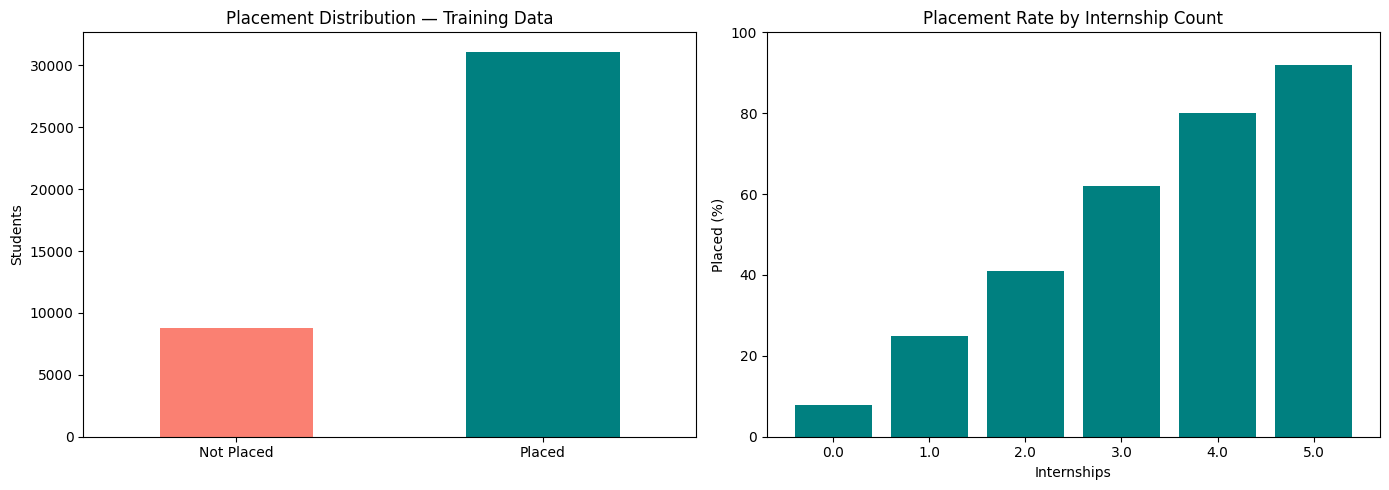

,Students,Placement_Rate
Internships,,
0.0,51,0.078
1.0,509,0.250
2.0,2695,0.410
3.0,7788,0.619
4.0,12153,0.802
5.0,16667,0.919


In [20]:
placement_counts = (
    train_df["Placement_Status"]
    .value_counts()
    .reindex(["Not Placed", "Placed"])
)

internship_summary = (
    train_df.assign(
        Placed=train_df["Placement_Status"].eq("Placed").astype(int)
    )
    .groupby("Internships")["Placed"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Students",
        "mean": "Placement_Rate"
    })
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

placement_counts.plot.bar(
    ax=axes[0],
    color=["salmon", "teal"],
    rot=0
)

axes[0].set_title("Placement Distribution — Training Data")
axes[0].set_xlabel("")
axes[0].set_ylabel("Students")

axes[1].bar(
    internship_summary.index.astype(str),
    internship_summary["Placement_Rate"] * 100,
    color="teal"
)

axes[1].set_title("Placement Rate by Internship Count")
axes[1].set_xlabel("Internships")
axes[1].set_ylabel("Placed (%)")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.savefig(output_dir / "01_placement_and_internships.png", dpi=150)
plt.show()

display(internship_summary.round(3))

majority_rate = placement_counts.max() / placement_counts.sum()
rate_2 = internship_summary.loc[2, "Placement_Rate"]
rate_5 = internship_summary.loc[5, "Placement_Rate"]


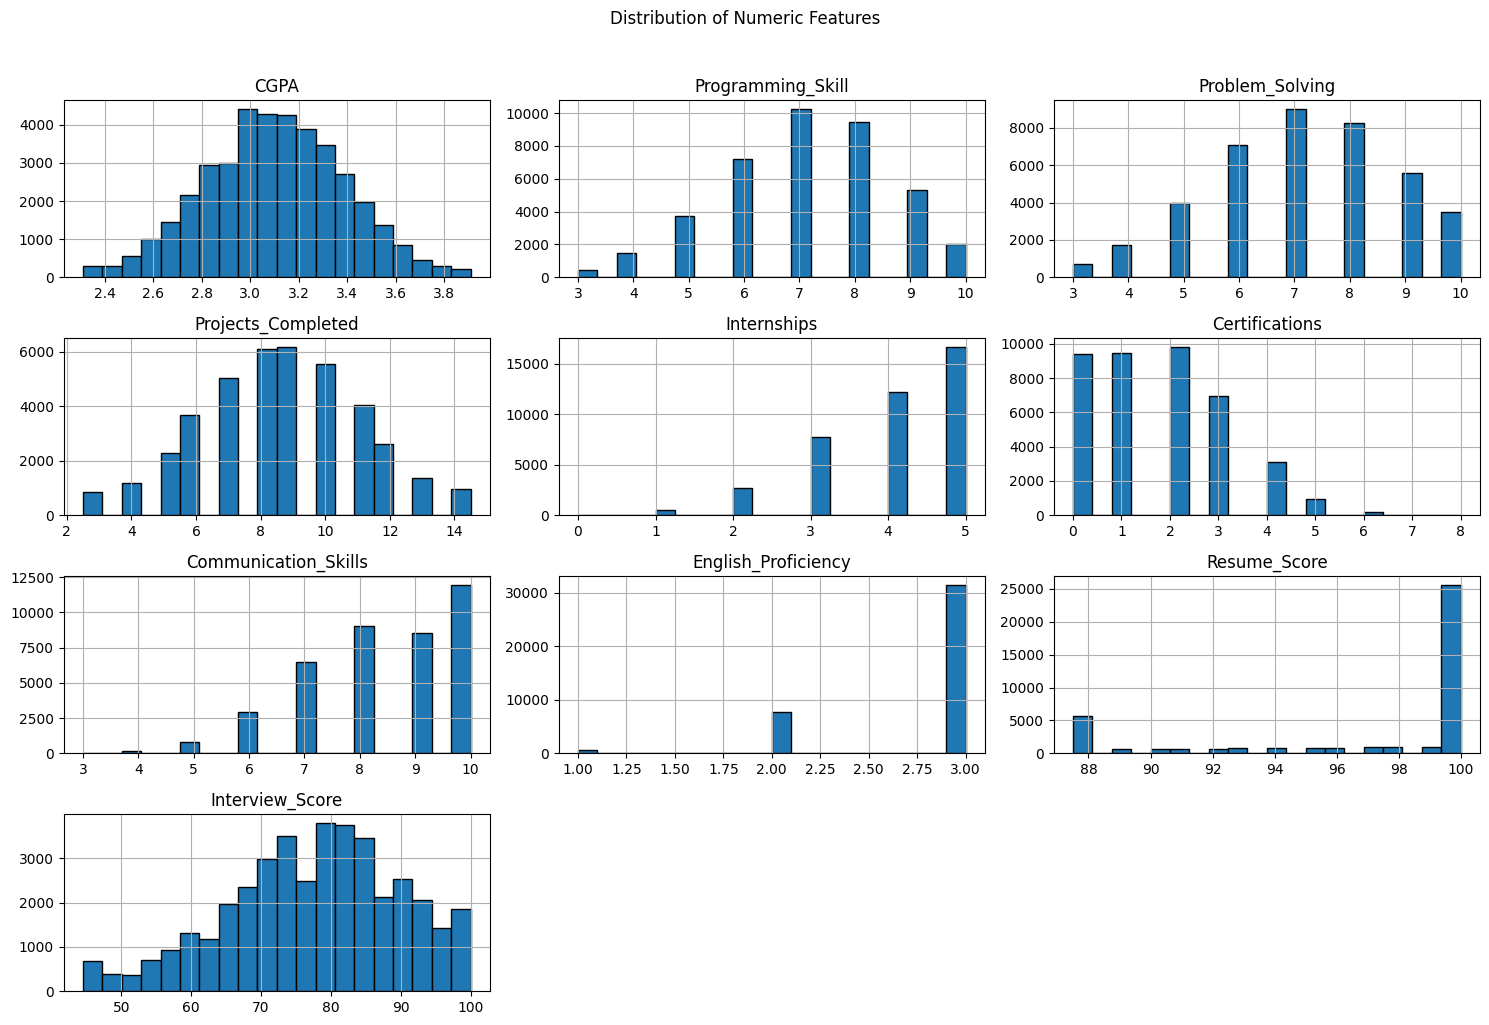

In [21]:
num_cols = [c for c in selected_features if c != "Leadership_Experience"]

train_df[num_cols].hist(bins=20, figsize=(15,10), edgecolor="black")
plt.suptitle("Distribution of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()

,Programming_Skill,Communication_Skills,Problem_Solving
Placement_Status,,,
Not Placed,6.09,7.70,6.09
Placed,7.43,8.63,7.48


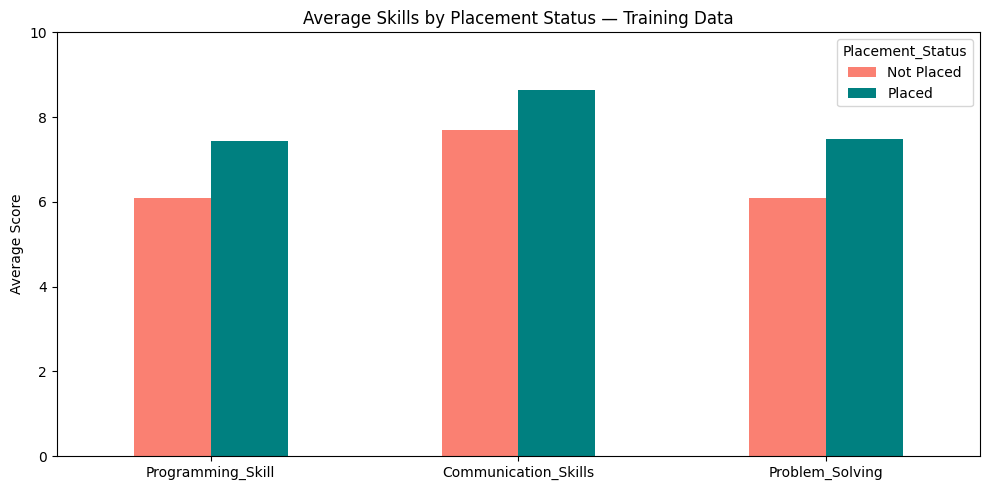

In [22]:
skills = [
    "Programming_Skill",
    "Communication_Skills",
    "Problem_Solving"
]

skill_means = (
    train_df.groupby("Placement_Status")[skills]
    .mean()
    .reindex(["Not Placed", "Placed"])
)

display(skill_means.round(2))

skill_means.T.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    color=["salmon", "teal"]
)

plt.title("Average Skills by Placement Status — Training Data")
plt.xlabel("")
plt.ylabel("Average Score")
plt.ylim(0, 10)
plt.tight_layout()

plt.savefig(output_dir / "02_skills_and_placement.png", dpi=150)
plt.show()

placed_score = skill_means.loc["Placed", "Programming_Skill"]
not_placed_score = skill_means.loc["Not Placed", "Programming_Skill"]


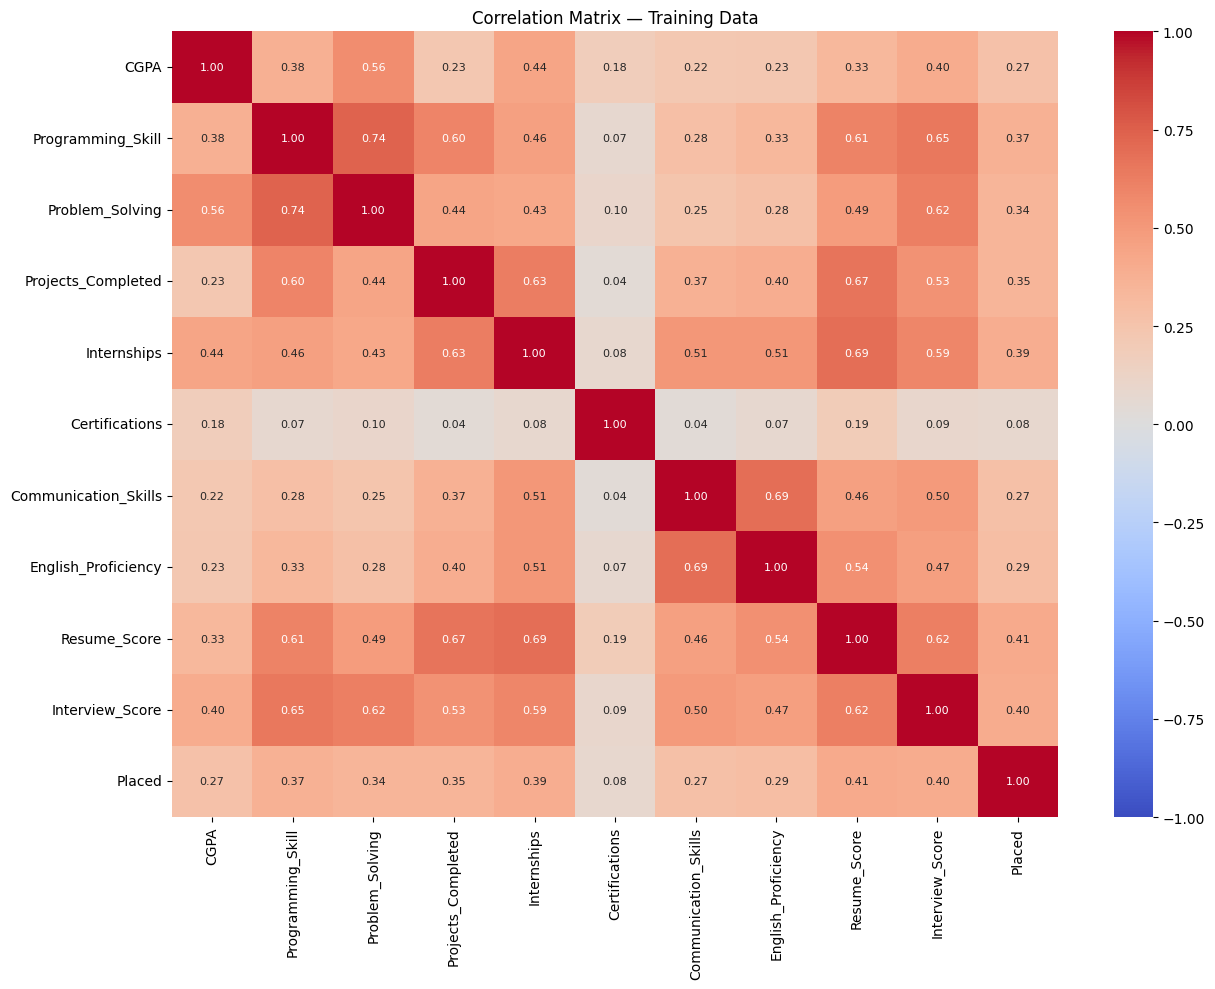

,Pearson_r
Resume_Score,0.413
Interview_Score,0.399
Internships,0.391
Programming_Skill,0.368
Projects_Completed,0.346
Problem_Solving,0.344
English_Proficiency,0.292
Communication_Skills,0.275
CGPA,0.272
Certifications,0.085


In [23]:
correlation_data = train_df.select_dtypes(
    include="number"
).copy()

correlation_data["Placed"] = (
    train_df["Placement_Status"]
    .map({"Not Placed": 0, "Placed": 1})
)

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot_kws={"size": 8}
)

plt.title("Correlation Matrix — Training Data")
plt.tight_layout()

plt.savefig(output_dir / "03_correlation.png", dpi=150)
plt.show()

target_correlations = (
    correlation_matrix["Placed"]
    .drop("Placed")
    .sort_values(key=abs, ascending=False)
)

display(target_correlations.round(3).to_frame("Pearson_r"))


In [24]:
print(f"Placement rate with 2 internships: {rate_2:.1%}")
print(f"Placement rate with 5 internships: {rate_5:.1%}")
print(f"Average programming score - placed: {placed_score:.2f}; not placed: {not_placed_score:.2f}")
print(f"Largest absolute numeric correlation with placement: {target_correlations.index[0]} ({target_correlations.iloc[0]:.3f})")
print(f"Majority-class baseline on training: {majority_rate:.1%}")


Placement rate with 2 internships: 41.0%
Placement rate with 5 internships: 91.9%
Average programming score - placed: 7.43; not placed: 6.09
Largest absolute numeric correlation with placement: Resume_Score (0.413)
Majority-class baseline on training: 78.0%


In [25]:
X_train_original = train_df.drop(
    columns="Placement_Status"
).copy()

X_test_original = test_df.drop(
    columns="Placement_Status"
).copy()

X_train = X_train_original.copy()
X_test = X_test_original.copy()

y_train = train_df["Placement_Status"].map({
    "Not Placed": 0,
    "Placed": 1
}).astype(int)

y_test = test_df["Placement_Status"].map({
    "Not Placed": 0,
    "Placed": 1
}).astype(int)

for frame in [X_train, X_test]:

    soft_cols = [c for c in ["Communication_Skills", "Teamwork", "Problem_Solving"] if c in frame.columns]
    if soft_cols:
        frame["Soft_Skills_Average"] = frame[soft_cols].mean(axis=1)

    proj_cols = [c for c in ["Projects_Completed", "Internships", "Hackathons"] if c in frame.columns]
    if proj_cols:
        frame["Practical_Exposure_Score"] = frame[proj_cols].sum(axis=1)

print("Training inputs:", X_train.shape)
print("Test inputs:", X_test.shape)

Training inputs: (39863, 12)
Test inputs: (9966, 12)


In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

numeric_columns = X_train.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns)
])

train_array = preprocessor.fit_transform(X_train)
test_array = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_ready = pd.DataFrame(
    train_array,
    columns=feature_names,
    index=X_train.index
)

X_test_ready = pd.DataFrame(
    test_array,
    columns=feature_names,
    index=X_test.index
)

print("Final training matrix:", X_train_ready.shape)
print("Final test matrix:", X_test_ready.shape)
display(X_train_ready.head())

Final training matrix: (39863, 12)
Final test matrix: (9966, 12)


,numeric__CGPA,numeric__Programming_Skill,numeric__Problem_Solving,numeric__Projects_Completed,numeric__Internships,numeric__Certifications,numeric__Communication_Skills,numeric__English_Proficiency,numeric__Resume_Score,numeric__Interview_Score,numeric__Soft_Skills_Average,numeric__Practical_Exposure_Score
21782,-0.121878,-0.755556,-0.704138,-1.051240,-0.043723,-0.520805,-1.741773,-1.73846,-0.858490,-0.282397,-1.487623,-0.825333
47461,0.568181,0.575953,0.497834,0.158604,-0.043723,-1.249231,1.130238,0.49732,0.632557,-0.282397,0.993474,0.108718
39669,-0.225387,-0.089802,-0.103152,0.158604,-0.043723,0.207621,-0.305768,0.49732,0.632557,1.002529,-0.247074,0.108718
20316,-0.294393,1.241707,0.497834,0.965168,-0.043723,-1.249231,0.412235,0.49732,0.632557,1.163144,0.579958,0.731419
16365,1.120229,1.241707,1.699805,2.376653,0.947715,-1.249231,1.130238,0.49732,0.632557,1.002529,1.820507,2.132497


In [27]:
train_ids = set(student_ids.loc[train_df.index])
test_ids = set(student_ids.loc[test_df.index])
train_hashes = set(pd.util.hash_pandas_object(X_train_original, index=False))
test_hashes = set(pd.util.hash_pandas_object(X_test_original, index=False))

readiness = pd.DataFrame({
    "Check": ["Training rows", "Test rows", "Numeric predictor columns",
              "Missing training cells", "Missing test cells", "Overlapping students",
              "Identical predictor rows across splits"],
    "Result": [len(X_train_ready), len(X_test_ready), X_train_ready.shape[1],
               X_train_ready.isna().sum().sum(), X_test_ready.isna().sum().sum(),
               len(train_ids & test_ids), len(train_hashes & test_hashes)]
})
display(readiness)

checks_ok = (
    not (train_ids & test_ids) 
    and X_train_ready.columns.equals(X_test_ready.columns)
    and X_train_ready.index.equals(y_train.index)
    and X_test_ready.index.equals(y_test.index)
    and np.isfinite(X_train_ready.to_numpy()).all()
    and np.isfinite(X_test_ready.to_numpy()).all()
)

if not checks_ok:
    raise ValueError("Data readiness checks failed. Review the table above.")
print("Data readiness checks passed.")

,Check,Result
0,Training rows,39863
1,Test rows,9966
2,Numeric predictor columns,12
3,Missing training cells,0
4,Missing test cells,0
5,Overlapping students,0
6,Identical predictor rows across splits,5


Data readiness checks passed.


In [28]:
before_after = pd.DataFrame({
    "Metric": [
        "Records",
        "Predictor columns",
        "Text predictor columns",
        "Training records",
        "Test records"
    ],
    "Before": [
        len(model_data),
        len(selected_features),
        1,
        0,
        0
    ],
    "After": [
        len(X_train_ready) + len(X_test_ready),
        X_train_ready.shape[1],
        0,
        len(X_train_ready),
        len(X_test_ready)
    ]
})

display(before_after)

,Metric,Before,After
0,Records,49829,49829
1,Predictor columns,10,12
2,Text predictor columns,1,0
3,Training records,0,39863
4,Test records,0,9966


In [29]:
df_cleaned.to_csv(
    output_dir / "milestone2_cleaned_dataset.csv",
    index=False
)

for split, X_ready, y in [
    ("train", X_train_ready, y_train),
    ("test", X_test_ready, y_test)
]:
    X_ready.to_csv(
        output_dir / f"X_{split}.csv",
        index=False,
        float_format="%.12g"
    )

    y.rename("Placement_Status").to_csv(
        output_dir / f"y_{split}.csv",
        index=False
    )

    saved_X = pd.read_csv(output_dir / f"X_{split}.csv")
    saved_y = pd.read_csv(output_dir / f"y_{split}.csv")

    if saved_X.shape != X_ready.shape or saved_y.shape != (len(X_ready), 1):
        raise ValueError("Saved dataset dimensions do not match.")

In [30]:
membership = pd.concat([
    pd.DataFrame({
        "Student_ID": df.loc[
            train_df.index, "Student_ID"
        ].to_numpy(),
        "Split": "train",
        "Row_Position": np.arange(len(train_df))
    }),
    pd.DataFrame({
        "Student_ID": df.loc[
            test_df.index, "Student_ID"
        ].to_numpy(),
        "Split": "test",
        "Row_Position": np.arange(len(test_df))
    })
], ignore_index=True)

membership.to_csv(
    output_dir / "split_membership.csv",
    index=False
)

In [31]:
target_correlations.to_csv(
    output_dir / "target_correlations.csv"
)

internship_summary.to_csv(
    output_dir / "internship_summary.csv"
)

readiness.to_csv(
    output_dir / "readiness_checks.csv",
    index=False
)

before_after.to_csv(
    output_dir / "before_after.csv",
    index=False
)

print("Files saved and checked:", output_dir.resolve())

Files saved and checked: C:\Users\Hb\Desktop\Fursa_AI_Balanced\milestone3_outputs


In [32]:
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
log_reg.fit(X_train_ready, y_train)

coef_df = pd.DataFrame({
    "Feature": X_train_ready.columns,
    "Coefficient": log_reg.coef_[0]
}).sort_values("Coefficient", key=abs, ascending=False)

display(coef_df.round(3))                                      

,Feature,Coefficient
9,numeric__Interview_Score,0.313
1,numeric__Programming_Skill,0.264
4,numeric__Internships,0.228
0,numeric__CGPA,0.224
11,numeric__Practical_Exposure_Score,0.149
8,numeric__Resume_Score,0.105
10,numeric__Soft_Skills_Average,0.103
3,numeric__Projects_Completed,0.101
5,numeric__Certifications,0.090
2,numeric__Problem_Solving,0.086


In [33]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, 
        class_weight="balanced", 
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, 
        class_weight="balanced", 
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5, 
        n_jobs=-1
    )
}

model_results = []

for name, model in models.items():
    model.fit(X_train_ready, y_train)
    
    pred = model.predict(X_test_ready)
    proba = model.predict_proba(X_test_ready)[:, 1]
    
    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred)
    rec = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc = roc_auc_score(y_test, proba)
    
    model_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc
    })
    
    print(f"=== {name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"ROC-AUC  : {roc:.4f}\n")

comparison_df = pd.DataFrame(model_results).sort_values(by="ROC-AUC", ascending=False)
display(comparison_df)

=== Logistic Regression ===
Accuracy : 0.7488
Precision: 0.9058
Recall   : 0.7569
F1       : 0.8247
ROC-AUC  : 0.8098

=== Decision Tree ===
Accuracy : 0.7121
Precision: 0.9020
Recall   : 0.7080
F1       : 0.7933
ROC-AUC  : 0.7640

=== Random Forest ===
Accuracy : 0.7634
Precision: 0.8989
Recall   : 0.7852
F1       : 0.8382
ROC-AUC  : 0.8081

=== K-Nearest Neighbors ===
Accuracy : 0.7960
Precision: 0.8375
Recall   : 0.9164
F1       : 0.8752
ROC-AUC  : 0.7343



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.748846,0.905832,0.756878,0.824683,0.809803
2,Random Forest,0.763396,0.898881,0.785163,0.838183,0.808141
1,Decision Tree,0.712121,0.902048,0.708023,0.793344,0.763976
3,K-Nearest Neighbors,0.796006,0.837504,0.916431,0.875192,0.734277


In [34]:
best_model_name = "Logistic Regression" 
best_model = models[best_model_name]

joblib.dump(best_model, output_dir / "best_placement_model.pkl")

joblib.dump(preprocessor, output_dir / "preprocessor.pkl")

print(f"تم حفظ نموذج {best_model_name} ومعالج البيانات بنجاح!")

تم حفظ نموذج Logistic Regression ومعالج البيانات بنجاح!


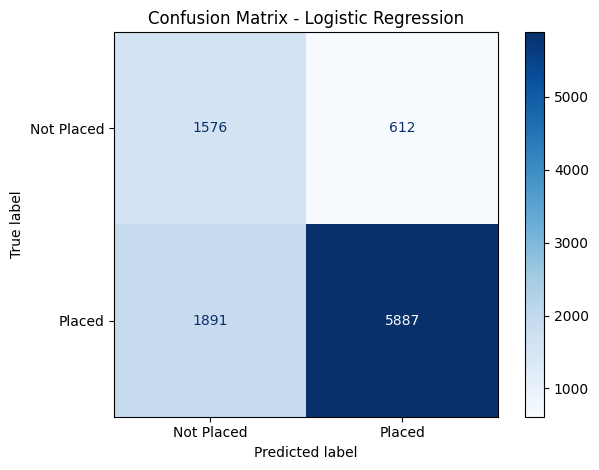

In [35]:
best_model = models["Logistic Regression"] 
y_pred_best = best_model.predict(X_test_ready)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Not Placed", "Placed"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()

plt.savefig(
    output_dir / "08_improved_confusion_matrix.png",
    dpi=150
)
plt.show()

In [36]:
predictions = best_model.predict(X_test_ready)
probabilities = best_model.predict_proba(X_test_ready)[:, 1]

errors = X_test_original.copy()
errors["Actual"] = y_test
errors["Predicted"] = predictions
errors["Model_Score"] = probabilities

errors = errors[errors["Actual"] != errors["Predicted"]]

display(errors.head(10))

errors.to_csv(
    output_dir / "prediction_errors.csv",
    index=False
)

,CGPA,Programming_Skill,Problem_Solving,Projects_Completed,Internships,Certifications,Communication_Skills,English_Proficiency,Resume_Score,Interview_Score,Actual,Predicted,Model_Score
39593,2.81,8.0,5.0,5.0,3.0,3.0,8.0,3.0,100.0,69.0,1,0,0.353351
13782,2.79,7.0,6.0,7.0,4.0,0.0,8.0,3.0,97.0,75.0,1,0,0.408805
26595,2.82,4.0,4.0,5.0,3.0,0.0,9.0,3.0,87.5,58.0,1,0,0.113750
30069,2.94,5.0,6.0,8.0,4.0,5.0,10.0,3.0,100.0,64.0,1,0,0.448795
31591,2.49,7.0,6.0,8.0,4.0,0.0,6.0,2.0,92.0,52.0,1,0,0.199097
46815,3.03,7.0,6.0,10.0,5.0,0.0,8.0,3.0,100.0,83.0,0,1,0.649850
24264,3.20,8.0,9.0,6.0,4.0,3.0,7.0,3.0,97.0,72.0,0,1,0.585514
25432,3.00,6.0,7.0,9.0,3.0,0.0,9.0,3.0,96.0,75.0,1,0,0.422536
36735,3.00,7.0,7.0,5.0,3.0,0.0,8.0,3.0,90.0,74.0,1,0,0.322785
28335,2.65,7.0,5.0,7.0,3.0,0.0,7.0,3.0,93.0,70.0,1,0,0.239565


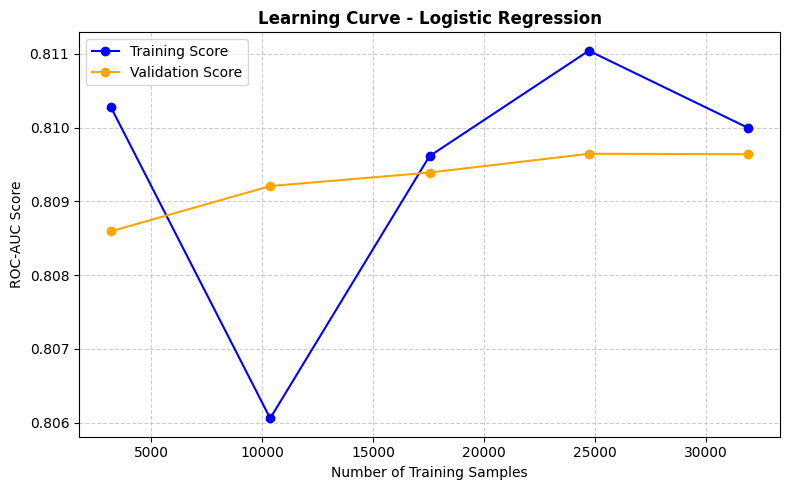

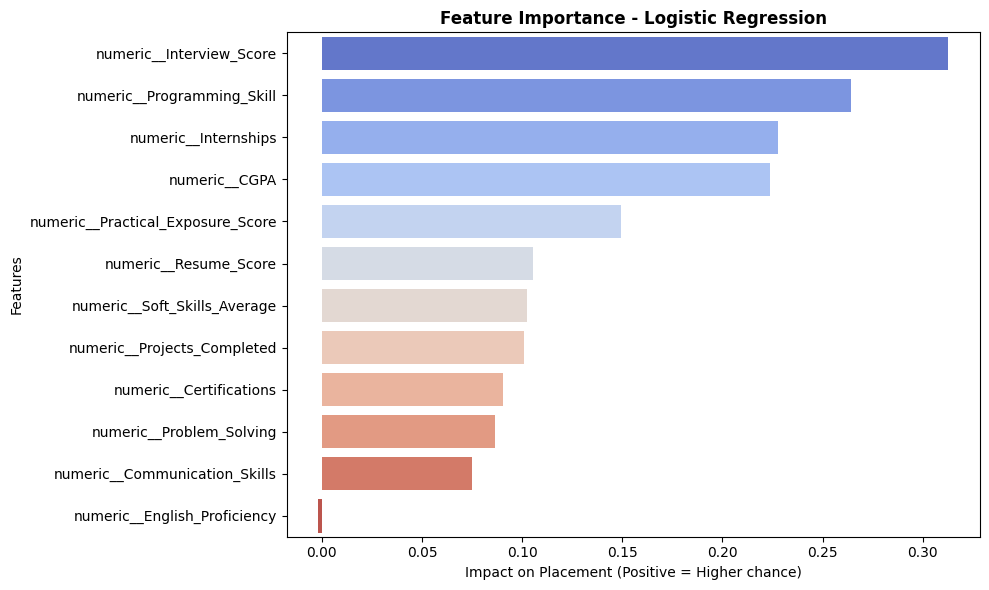

In [37]:
# ==========================================
# 1. رسم منحنى التعلم (Learning Curve)
# ==========================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_sizes, train_scores, test_scores, fit_times, score_times = learning_curve(
    best_model, 
    X_train_ready, 
    y_train, 
    cv=cv, 
    scoring='roc_auc', 
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    return_times=True 
)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color='blue', label='Training Score')
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color='orange', label='Validation Score')
plt.title('Learning Curve - Logistic Regression', fontweight='bold')
plt.xlabel('Number of Training Samples')
plt.ylabel('ROC-AUC Score')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(output_dir / "09_learning_curve.png", dpi=150)
plt.show()
# ==========================================
# 2. رسم أهم الميزات (Feature Importance)
# ==========================================
importances = best_model.coef_[0]

if hasattr(X_train_ready, 'columns'):
    feature_names = X_train_ready.columns
elif hasattr(preprocessor, 'get_feature_names_out'):
    feature_names = preprocessor.get_feature_names_out()
else:
    feature_names = [f"Feature {i}" for i in range(len(importances))]


fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances,
    'Abs_Importance': np.abs(importances)
}).sort_values(by='Abs_Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi_df, palette='coolwarm', hue='Feature', legend=False)
plt.title("Feature Importance - Logistic Regression", fontweight="bold")
plt.xlabel("Impact on Placement (Positive = Higher chance)")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig(output_dir / "10_feature_importance.png", dpi=150)
plt.show()

##  تشغيل الموقع


In [38]:
import subprocess
import sys
import socket
from pathlib import Path

project_folder = Path.cwd()
with socket.socket() as connection:
    port_busy = connection.connect_ex(("127.0.0.1", 8502)) == 0
if port_busy:
    print("Port 8502 is already in use. Open the running app or stop it first.")
else:
    log_file = open("streamlit.log", "w", encoding="utf-8")
    app_process = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "app.py",
         "--server.port", "8502", "--server.headless", "true"],
        cwd=project_folder, stdout=log_file, stderr=subprocess.STDOUT
    )
    log_file.close()
    print("Streamlit is starting. If it fails, read streamlit.log.")
print("Open: http://localhost:8502")

Port 8502 is already in use. Open the running app or stop it first.
Open: http://localhost:8502
